# Kinh doanh sách: nghiên cứu mô phỏng có kiểm chứng

**Dữ liệu mô phỏng hoàn toàn; không đại diện thị trường.** Notebook dùng cùng hàm với pipeline. Một dòng là một đơn một đầu sách giả lập. Mọi con số dưới đây được tính khi chạy; phần diễn giải và tài liệu tham khảo đầy đủ nằm trong `report/bao_cao.pdf` và `docs/QUY-TRINH.md`.

Mục tiêu: xây dựng dữ liệu, kiểm chứng làm sạch, trả lời bảy câu hỏi EDA và đánh giá độ nhạy. Không suy ra lợi nhuận, chuyển đổi hay tác động nhân quả. Chạy `python run.py` trước để tạo các dữ liệu và kết quả thí nghiệm.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from src.data_cleaner import clean
from src.analysis import summarize, evaluate
from src.visualizer import generate_all_charts
pd.set_option('display.max_columns',12)
pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
raw=pd.read_csv(ROOT/'data/raw/book_sales_raw.csv')
catalog=pd.read_csv(ROOT/'data/reference/catalog.csv')
print('Dòng/cột raw:',raw.shape,'; số mã sách trong catalog:',len(catalog))
display(raw.head())

Dòng/cột raw: (6660, 16) ; số mã sách trong catalog: 300


,raw_row_id,ma_sach,ten_sach,the_loai,tac_gia,nha_xuat_ban,...,kenh_ban,ma_dong,ma_don,giam_gia_niem_yet,gia_ban,so_luong
0,R000001,BK0279,Sách mô phỏng 279,Nuôi dạy con,Tác giả giả lập 03,NXB giả lập 08,...,Sàn C,L005831,O005831,25,123000,3
1,R000002,BK0058,Sách mô phỏng 058,Văn học,Tác giả giả lập 07,NXB giả lập 08,...,Sàn B,L003316,O003316,5,76000,2
2,R000003,BK0001,Sách mô phỏng 001,Kỹ năng sống,Tác giả giả lập 04,NXB giả lập 03,...,Sàn B,L000753,O000753,25,113000,10
3,R000004,BK0007,Sách mô phỏng 007,Kỹ năng sống,Tác giả giả lập 04,NXB giả lập 03,...,Sàn A,L003188,O003188,15,61000,4
4,R000005,BK0152,Sách mô phỏng 152,Khoa học công nghệ,Tác giả giả lập 12,NXB giả lập 08,...,Sàn A,L005320,O005320,20,83000,3


## 1. Khảo sát dữ liệu thô

Đếm riêng bản sao cùng mã và ô thiếu. Số mã lặp không tự quyết định số dòng bị xóa: cần xem nội dung có giống nhau sau chuẩn hóa hay không.

In [2]:
display(pd.DataFrame({'dtype':raw.dtypes.astype(str),'missing':raw.isna().sum()}))
print('Mã dòng lặp:',raw.ma_dong.duplicated().sum())

,dtype,missing
raw_row_id,object,0
ma_sach,object,0
ten_sach,object,0
the_loai,object,0
tac_gia,object,132
nha_xuat_ban,object,132
nam_xuat_ban,float64,133
gia_goc,int64,0
diem_danh_gia,float64,132
ngay_ban,object,0


Mã dòng lặp: 160


## 2. Làm sạch dùng chung quy tắc

Hàm chỉ nhận raw và catalog, không nhận truth hoặc nhãn lỗi. Quy trình: chuẩn hóa → phục hồi có căn cứ → gộp bản sao giống nhau → cách ly xung đột → gắn cờ IQR → tạo đặc trưng. Chi tiết và lý do từng bước ở `docs/QUY-TRINH.md`.

In [3]:
df,stages,quarantine,changes,lineage=clean(raw,catalog)
display(stages)
display(quarantine.groupby('ly_do').size().rename('so_dong'))
assert len(lineage)==len(raw)==lineage.raw_row_id.nunique()
assert not df.ma_dong.duplicated().any()
display(changes.head(10))

,buoc,so_dong,o_thieu,ma_dong_lap
0,01. Nạp dữ liệu,6660,529,160
1,02. Chuẩn hóa và khôi phục có căn cứ,6660,0,160
2,03. Gộp bản sao cùng mã và cùng nội dung,6505,0,5
3,04. Cách ly bất thường và xung đột,6480,0,0


ly_do
conflicting_line_id      10
quantity_needs_review    15
Name: so_dong, dtype: int64

,raw_row_id,ma_dong,cot,truoc,sau
0,R000015,L005841,the_loai,KHOA HỌC CÔNG NGHỆ,Khoa học công nghệ
1,R000033,L003096,the_loai,KỸ NĂNG SỐNG,Kỹ năng sống
2,R000052,L005168,the_loai,TÂM LÝ HỌC,Tâm lý học
3,R000056,L004040,the_loai,KỸ NĂNG SỐNG,Kỹ năng sống
4,R000135,L001164,the_loai,THIẾU NHI,Thiếu nhi
5,R000138,L005020,the_loai,KỸ NĂNG SỐNG,Kỹ năng sống
6,R000156,L002418,the_loai,THIẾU NHI,Thiếu nhi
7,R000198,L005152,the_loai,KỸ NĂNG SỐNG,Kỹ năng sống
8,R000206,L001104,the_loai,LỊCH SỬ - TRIẾT HỌC,Lịch sử - Triết học
9,R000215,L006454,the_loai,VĂN HỌC,Văn học


## 3. Đối soát kết quả và phục hồi

Chỉ từ bước đánh giá mới đọc dữ liệu chuẩn. So sánh theo mã dòng; kiểm tra cả tính đúng của dòng giữ lại và chênh lệch tổng kỳ do cách ly.

In [4]:
stored=pd.read_csv(ROOT/'data/processed/book_sales_clean.csv')
pd.testing.assert_frame_equal(df.astype('string').reset_index(drop=True),stored.astype('string').reset_index(drop=True))
truth=pd.read_csv(ROOT/'data/reference/ground_truth.csv')
errors=pd.read_csv(ROOT/'data/audit/injected_errors.csv')
recovery,validation=evaluate(truth,df,raw,errors)
display(recovery)
display(pd.Series(validation,name='gia_tri'))
tables,metrics=summarize(df)
published=json.loads((ROOT/'results/metrics.json').read_text(encoding='utf8'))
# So sánh có dung sai: hai môi trường có thể lệch nhau ở chữ số cuối của phép tính dấu phẩy
# động (thư viện BLAS khác nhau). Sai khác thực vẫn làm notebook dừng.
assert metrics.keys()==published['metrics'].keys(), sorted(set(metrics)^set(published['metrics']))
for k,v in metrics.items():
    old=published['metrics'][k]
    if isinstance(v,float):
        assert abs(v-old)<=1e-9*max(1,abs(old)), f'{k}: {v} != {old}'
    else:
        assert v==old, f'{k}: {v} != {old}'
print('KPI khớp results/metrics.json trong dung sai 1e-9 tương đối.')
display(pd.Series(metrics,name='gia_tri'))

,cot,so_khop,so_so_sanh,ty_le_khop
0,gia_ban,6480,6480,1.000
1,so_luong,6480,6480,1.000
2,doanh_thu,6480,6480,1.000
3,diem_danh_gia,6480,6480,1.000
4,nam_xuat_ban,6480,6480,1.000
5,tac_gia,6480,6480,1.000
6,nha_xuat_ban,6480,6480,1.000
7,the_loai,6480,6480,1.000


truth_revenue                2,978,555,000.000
clean_revenue                2,969,430,000.000
relative_revenue_error_pct              -0.306
retained_pct                            99.692
quarantine_precision                     1.000
quarantine_recall                        1.000
retained_revenue_error                   0.000
unresolved_missing                       0.000
Name: gia_tri, dtype: float64

KPI khớp results/metrics.json trong dung sai 1e-9 tương đối.


lines                        6,480.000
books                          300.000
orders                       6,480.000
revenue              2,969,430,000.000
quantity                    30,790.000
average_unit_price          96,441.377
yoy_pct                         -1.305
rating_qty_r                     0.009
rating_book_qty_r                0.117
discount_qty_r                   0.173
rating_known                 6,480.000
good_rating_pct                 74.182
iqr_flags                      179.000
Name: gia_tri, dtype: float64

## 4. EDA cơ bản và các bảng kết quả

Các biến phụ thuộc theo định nghĩa: giá trị bán hàng = giá × lượng; giảm giá thực tế từ giá bán/giá gốc. Pearson chỉ mô tả tương quan, không là bằng chứng nhân quả.

In [5]:
display(tables['describe'])
display(tables['discount'])

,bien,count,mean,std,min,25%,50%,75%,max
0,gia_goc,"6,480.000","131,800.000","64,494.368","45,000.000","85,750.000","117,000.000","157,000.000","350,000.000"
1,gia_ban,"6,480.000","109,214.506","56,494.015","27,000.000","69,000.000","96,000.000","134,000.000","350,000.000"
2,giam_gia_thuc_te,"6,480.000",17.227,12.348,0.000,5.333,15.172,25.320,40.741
3,so_luong,"6,480.000",4.752,6.544,1.000,3.000,4.000,6.000,200.000
4,doanh_thu,"6,480.000","458,245.370","629,898.558","38,000.000","255,750.000","392,000.000","572,000.000","29,160,000.000"
5,diem_danh_gia,"6,480.000",4.217,0.496,2.500,3.900,4.300,4.600,4.900


,nhom_giam_gia,n,median_qty,mean_qty,total_revenue
0,0–5%,1737,3.000,3.469,712860000
1,>15–25%,1398,5.000,5.120,668606000
2,>25–40%,1555,6.000,6.397,789868000
3,>5–15%,1790,4.000,4.279,798096000


## 5. Bảy câu hỏi kinh doanh trong kịch bản

Tất cả đồ thị được tạo lại từ chính `df` vừa làm sạch. Kết quả độ nhạy đã tính bởi pipeline được đọc từ CSV; notebook không âm thầm chạy lại 150 mô phỏng.

In [6]:
exp=pd.read_csv(ROOT/'results/sensitivity_runs.csv')
generate_all_charts(df,tables,exp,ROOT/'charts')

### Thể loại

So sánh giá trị và số cuốn trên hai trục riêng. Thứ hạng chịu ảnh hưởng trọng số thể loại đã đặt, không là thị phần thị trường.

,the_loai,doanh_thu,so_luong,so_dong,ty_trong
3,Kỹ năng sống,638410000,6122,1313,21.499
9,Văn học,546643000,5658,1192,18.409
2,Kinh tế - Quản trị,427745000,4537,970,14.405
6,Thiếu nhi,389078000,4166,868,13.103
8,Tâm lý học,295264000,3027,571,9.943
0,Giáo dục - Ngoại ngữ,191462000,2102,454,6.448
1,Khoa học công nghệ,156152000,1638,358,5.259
7,Truyện tranh,139278000,1445,305,4.690
4,Lịch sử - Triết học,107869000,1194,258,3.633
5,Nuôi dạy con,77529000,901,191,2.611


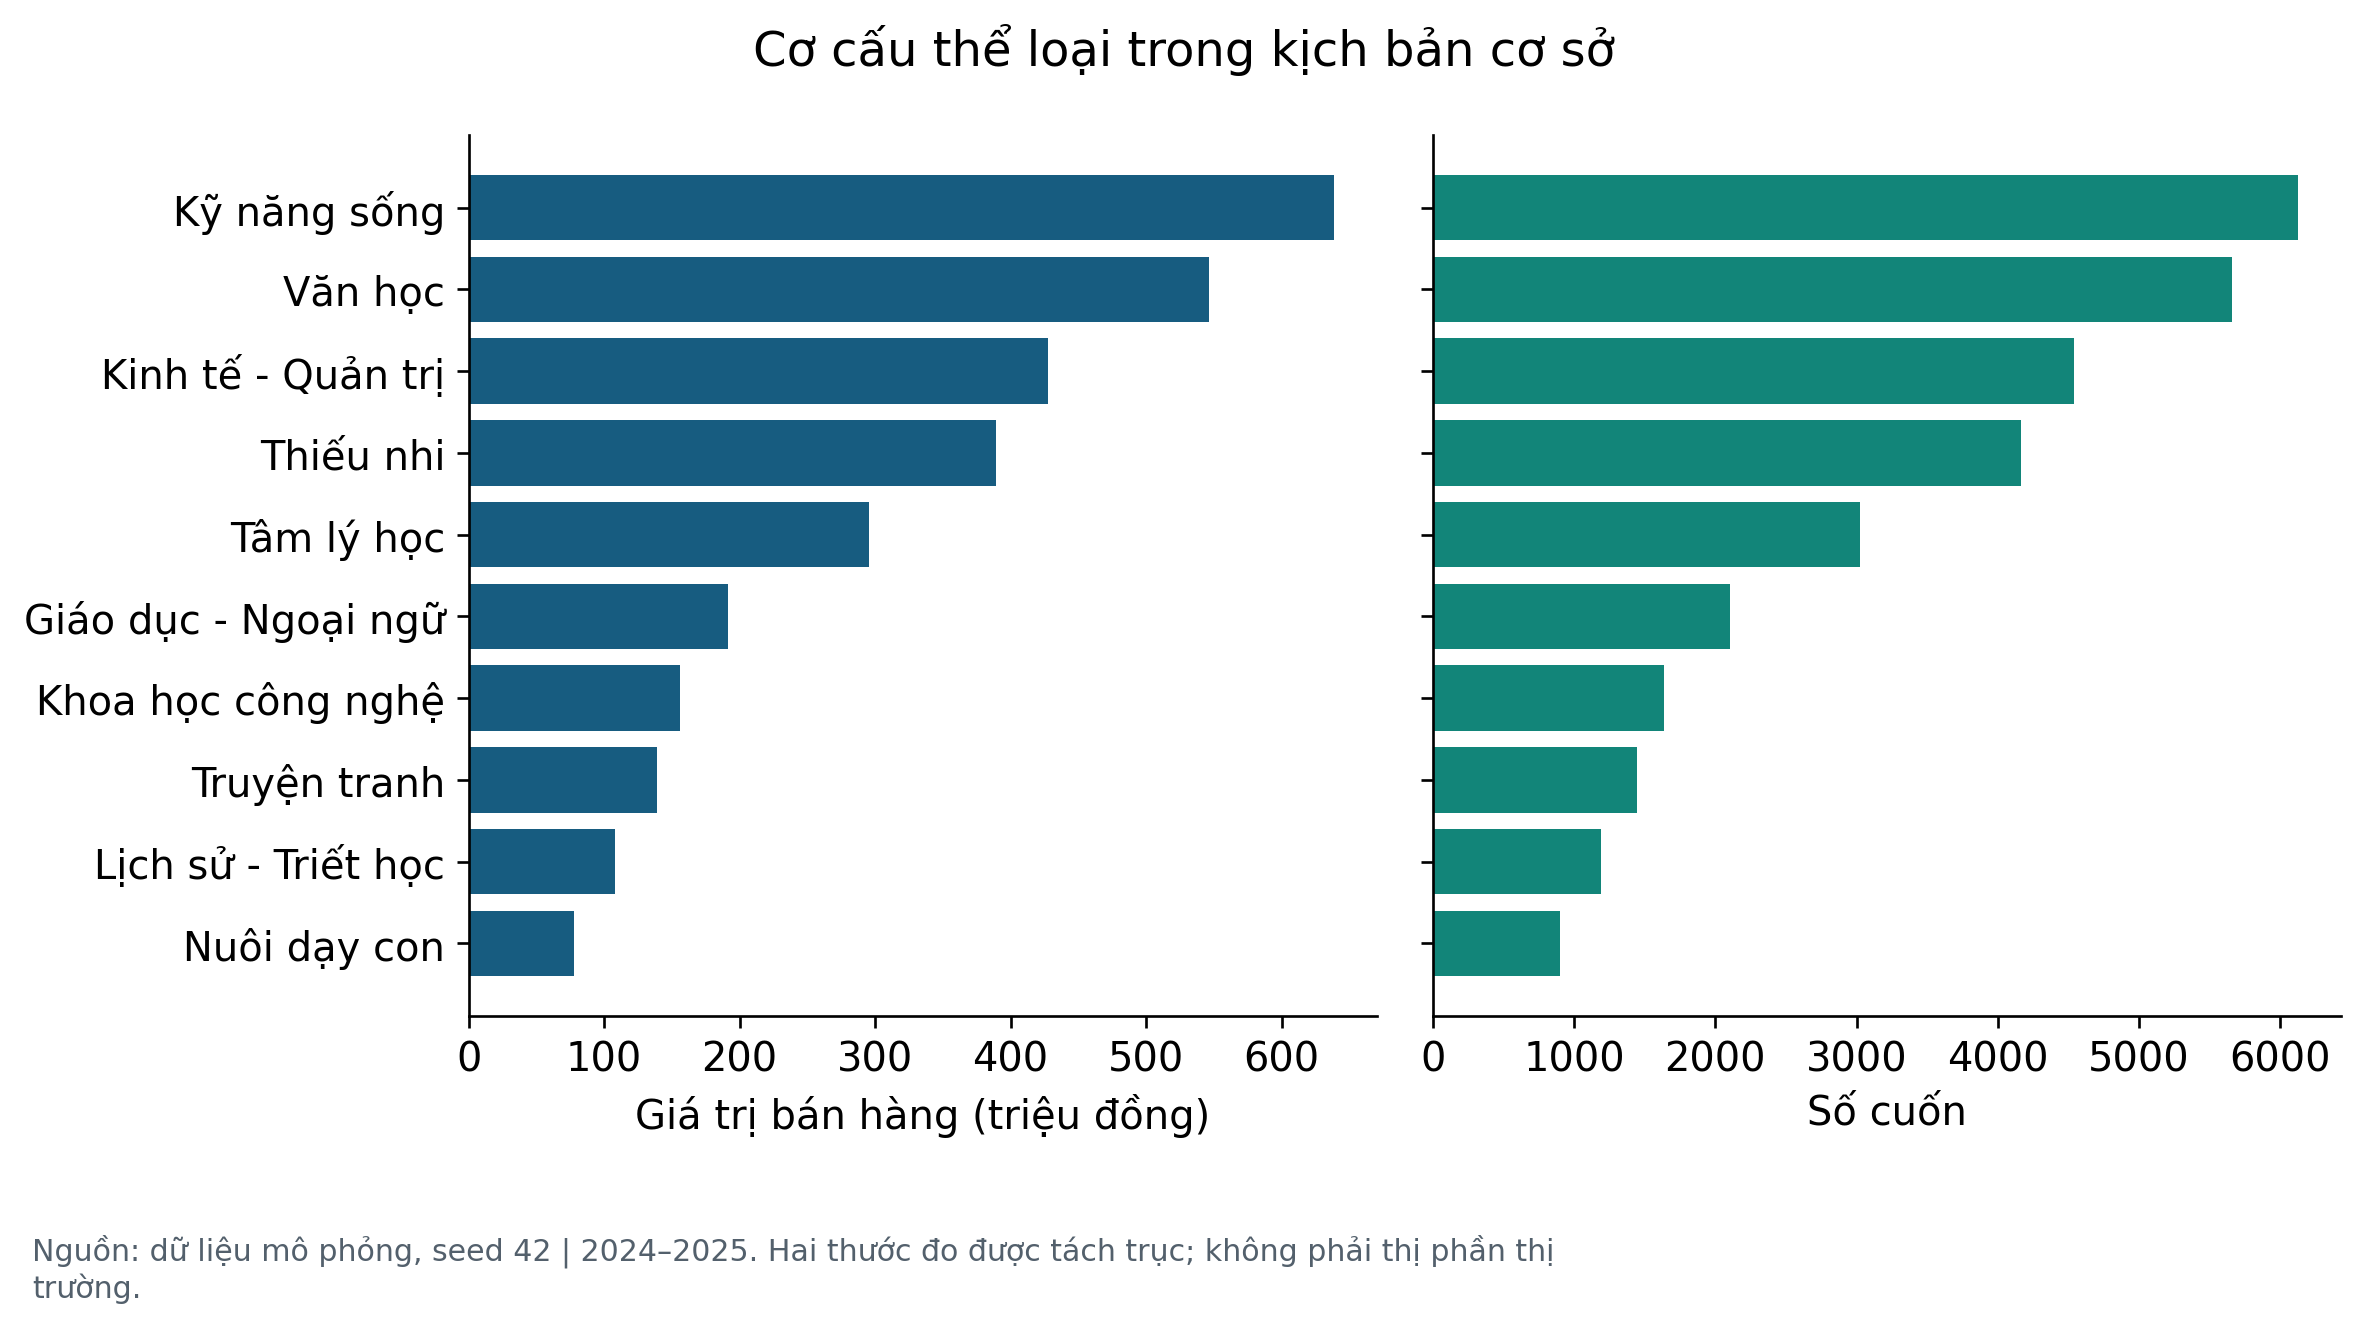

In [7]:
display(tables['genre'].head(24))
display(Image(filename=str(ROOT/'charts/01_genre.png')))

### Mã sách

Xếp theo mã sách, không theo tên hoặc tác giả thiếu. Đọc kèm số dòng và số cuốn để nhận biết ảnh hưởng mua số lượng lớn.

,ma_sach,ten_sach,doanh_thu,so_luong,so_dong,diem_danh_gia
8,BK0009,Sách mô phỏng 009,47701000,429,49,4.100
134,BK0135,Sách mô phỏng 135,41017000,267,26,3.700
15,BK0016,Sách mô phỏng 016,34880000,220,56,4.400
50,BK0051,Sách mô phỏng 051,31588000,164,44,4.400
21,BK0022,Sách mô phỏng 022,30275000,119,46,4.700
12,BK0013,Sách mô phỏng 013,30193000,173,48,3.800
75,BK0076,Sách mô phỏng 076,28772000,106,40,4.400
10,BK0011,Sách mô phỏng 011,27564000,257,50,4.400
36,BK0037,Sách mô phỏng 037,26782000,111,37,4.300
70,BK0071,Sách mô phỏng 071,26114000,177,41,4.600


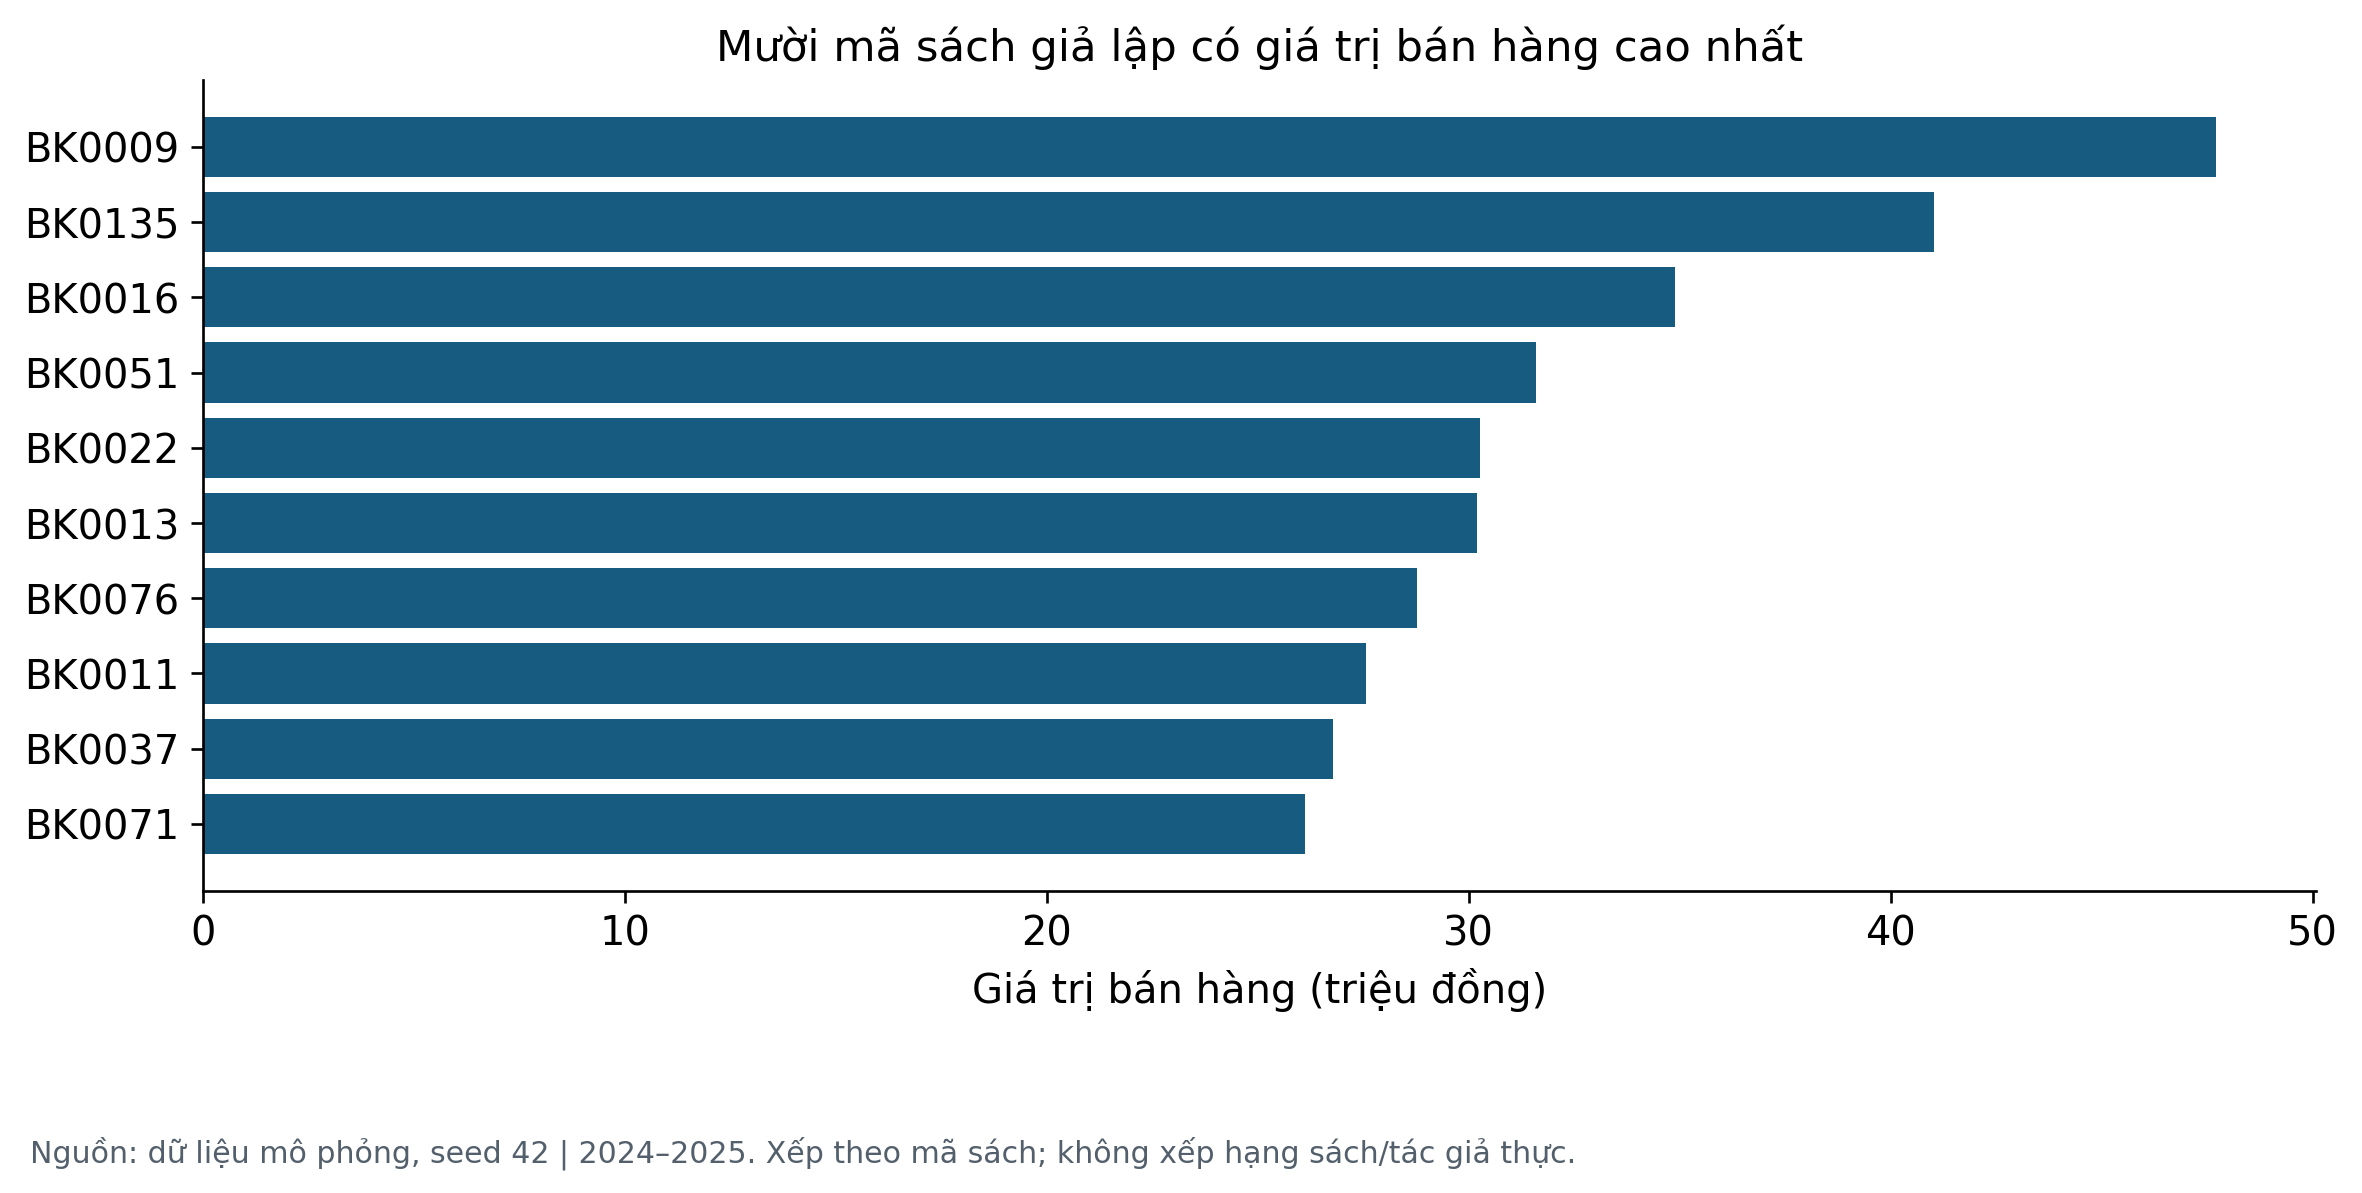

In [8]:
display(tables['books'].head(24))
display(Image(filename=str(ROOT/'charts/02_books.png')))

### Theo tháng

Hệ số mùa vụ đã được cài. Tăng trưởng giữa hai năm có thể do ngẫu nhiên; không gọi là tăng trưởng thị trường.

,thang_nam,doanh_thu,so_luong,so_dong,ty_trong
10,2024-11,167555000,1691,277,5.643
23,2025-12,167535000,1674,284,5.642
22,2025-11,163174000,1884,279,5.495
11,2024-12,147867000,1601,247,4.980
1,2024-02,143138000,1343,238,4.820
7,2024-08,137804000,1411,280,4.641
20,2025-09,135650000,1496,266,4.568
4,2024-05,135557000,1392,298,4.565
8,2024-09,133671000,1411,251,4.502
21,2025-10,128603000,1314,282,4.331


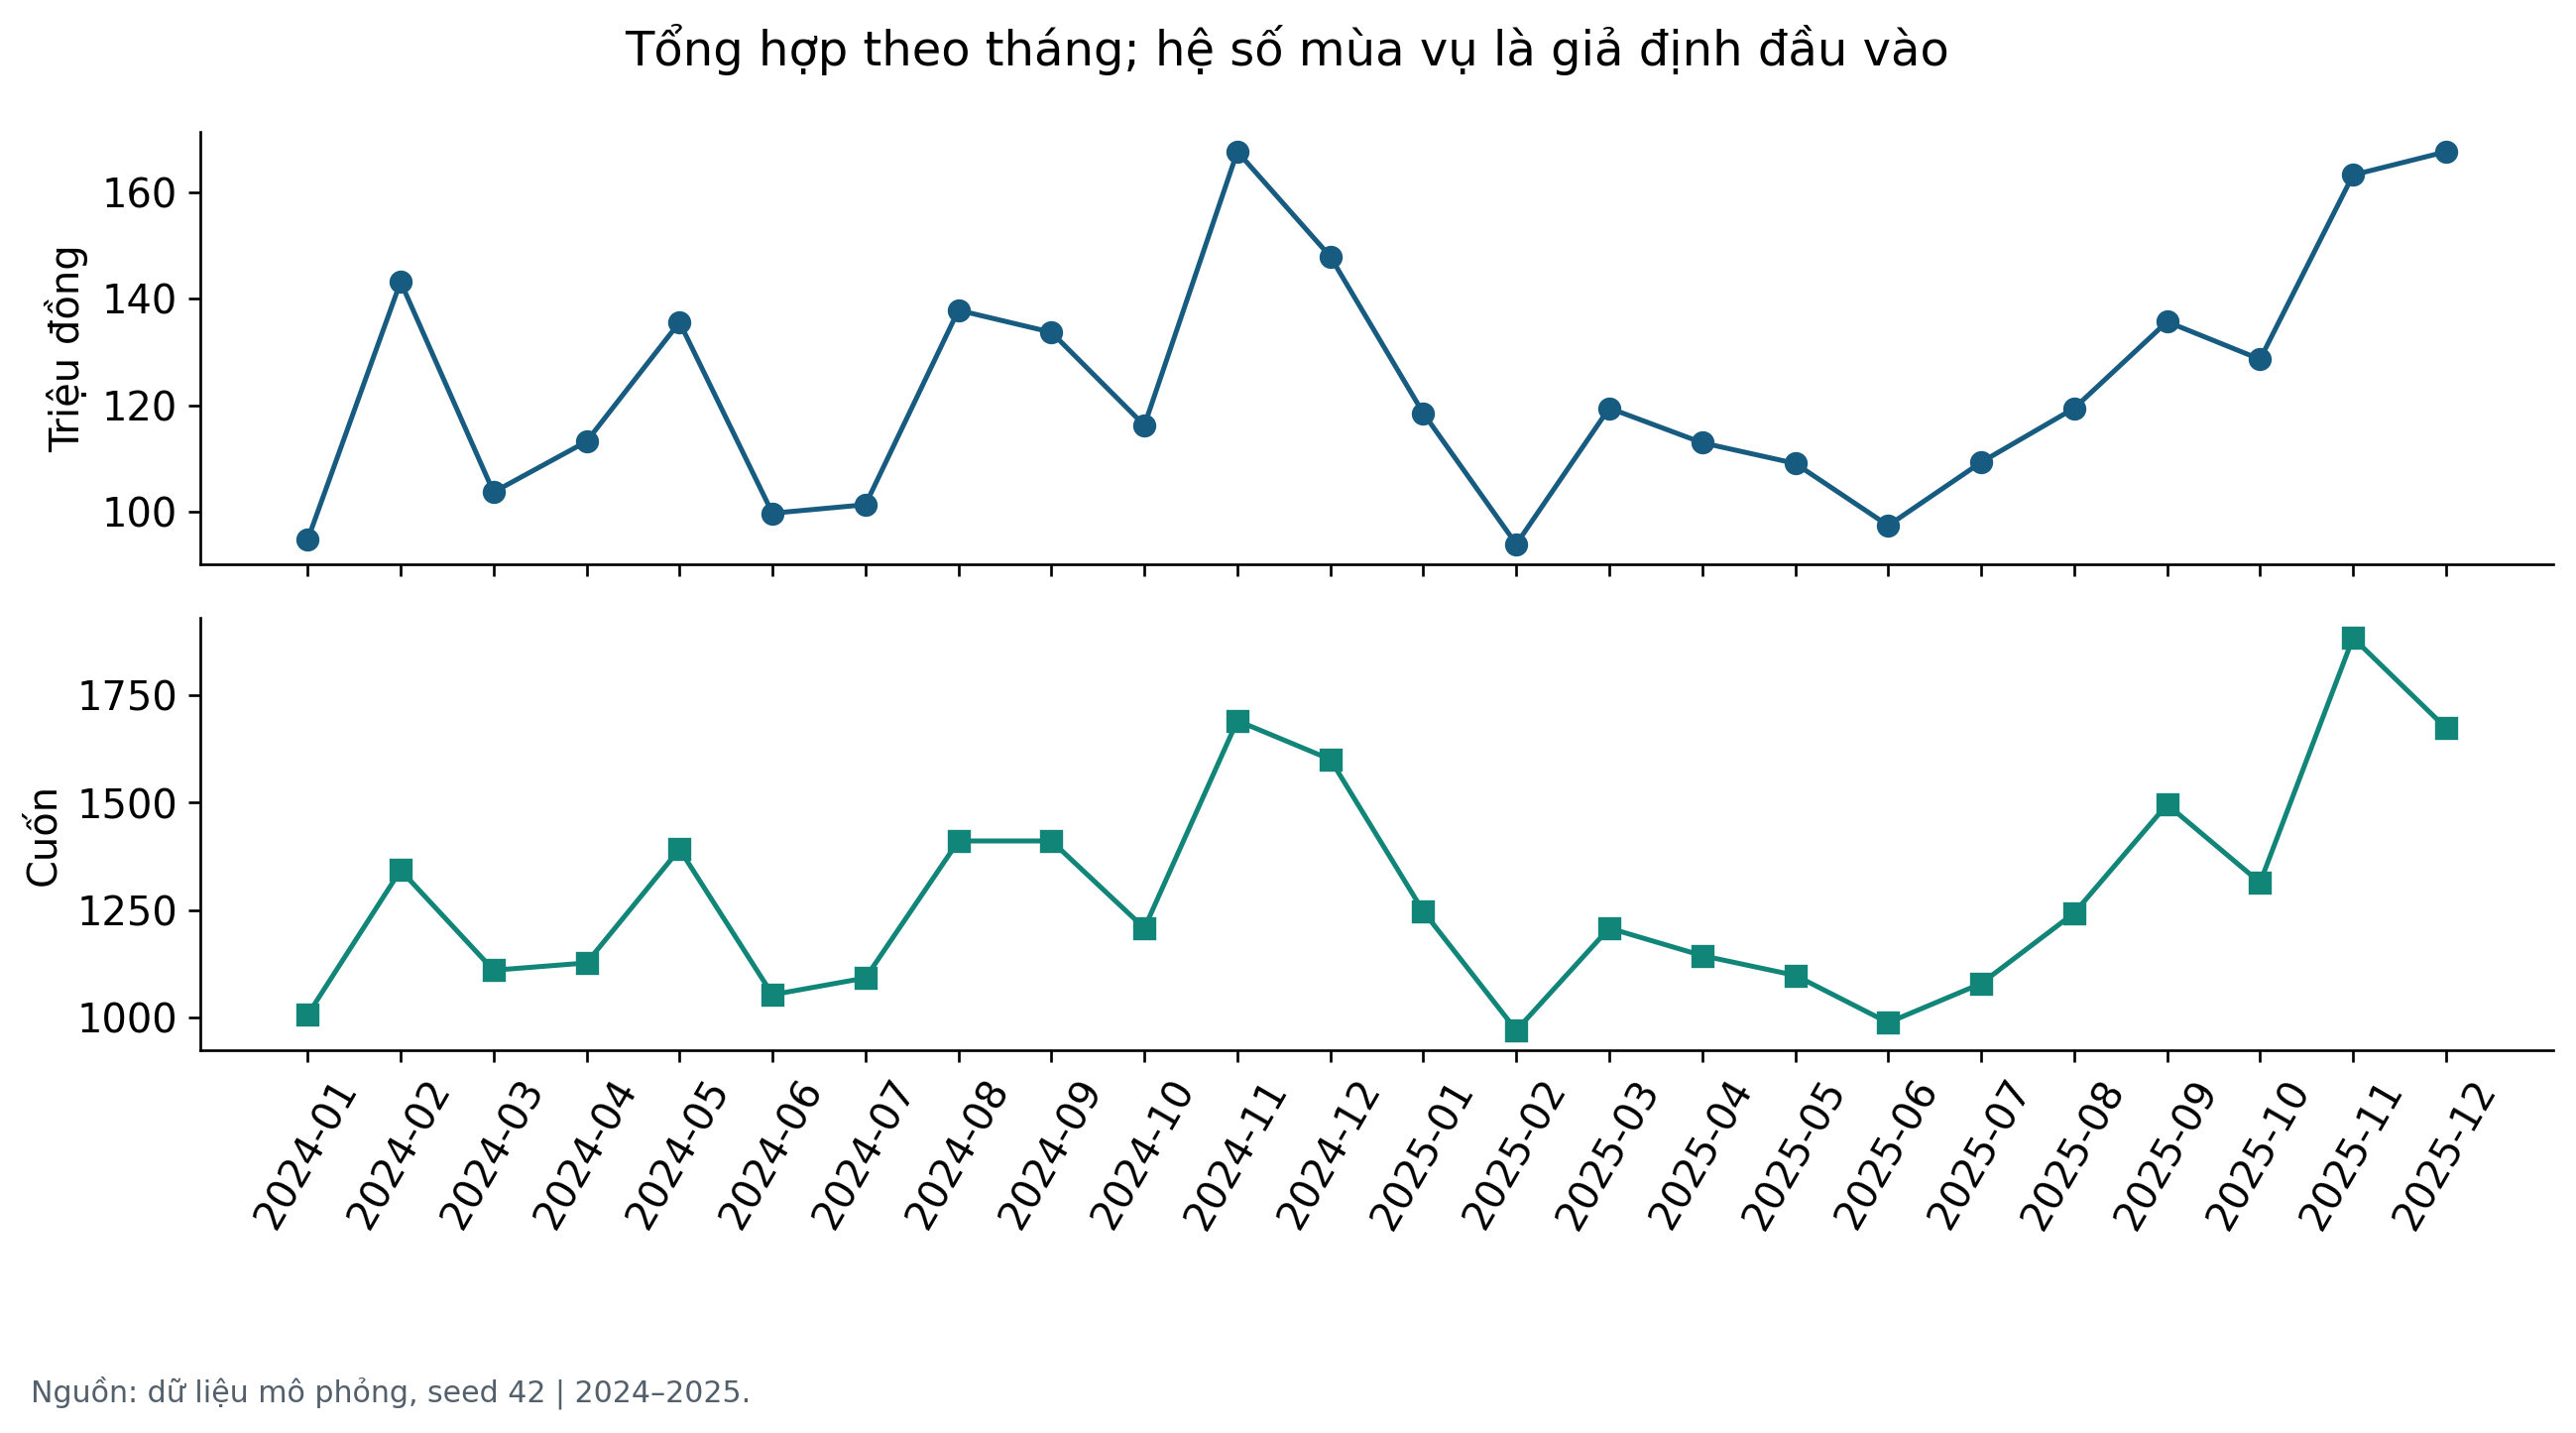

In [9]:
display(tables['month'].head(24))
display(Image(filename=str(ROOT/'charts/03_month.png')))

### Giá và giảm giá

Nhóm dùng mức giảm niêm yết; tương quan dùng mức thực tế. Giá và giảm giá đã có trong công thức sinh lượng.

,nhom_giam_gia,n,median_qty,mean_qty,total_revenue
0,0–5%,1737,3.000,3.469,712860000
1,>15–25%,1398,5.000,5.120,668606000
2,>25–40%,1555,6.000,6.397,789868000
3,>5–15%,1790,4.000,4.279,798096000


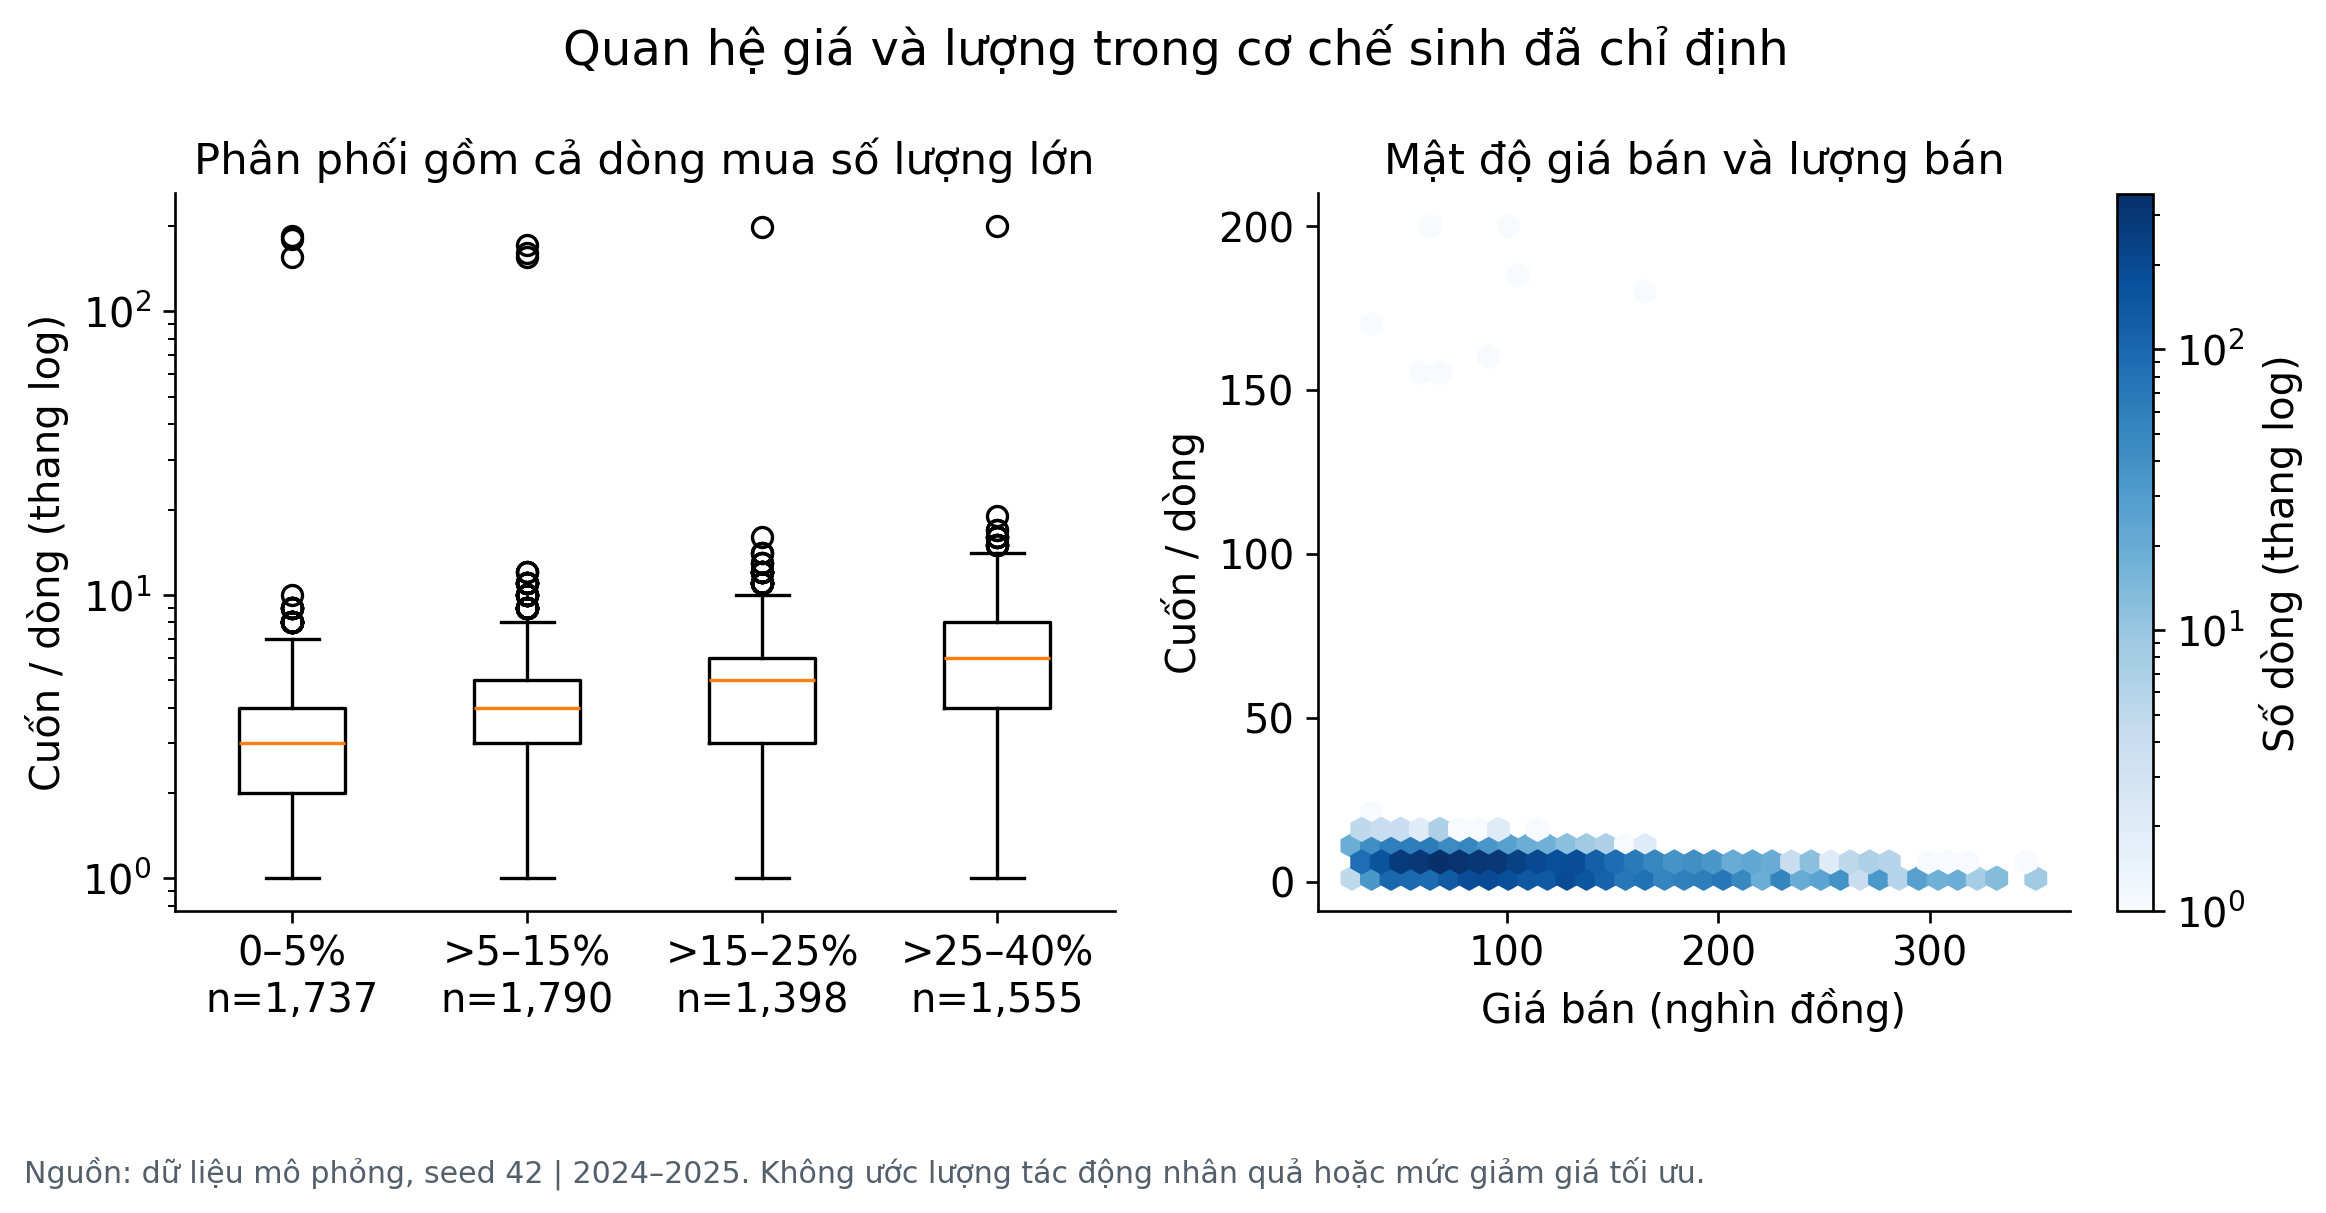

In [10]:
display(tables['discount'].head(24))
display(Image(filename=str(ROOT/'charts/04_discount.png')))

### Điểm và lượng theo sách

Điểm giả lập được cố định trước kỳ bán. Tổng hợp lên cấp sách để tránh đánh đồng dòng giao dịch với một sách độc lập.

,ma_sach,ten_sach,doanh_thu,so_luong,so_dong,diem_danh_gia
8,BK0009,Sách mô phỏng 009,47701000,429,49,4.100
134,BK0135,Sách mô phỏng 135,41017000,267,26,3.700
15,BK0016,Sách mô phỏng 016,34880000,220,56,4.400
50,BK0051,Sách mô phỏng 051,31588000,164,44,4.400
21,BK0022,Sách mô phỏng 022,30275000,119,46,4.700
12,BK0013,Sách mô phỏng 013,30193000,173,48,3.800
75,BK0076,Sách mô phỏng 076,28772000,106,40,4.400
10,BK0011,Sách mô phỏng 011,27564000,257,50,4.400
36,BK0037,Sách mô phỏng 037,26782000,111,37,4.300
70,BK0071,Sách mô phỏng 071,26114000,177,41,4.600


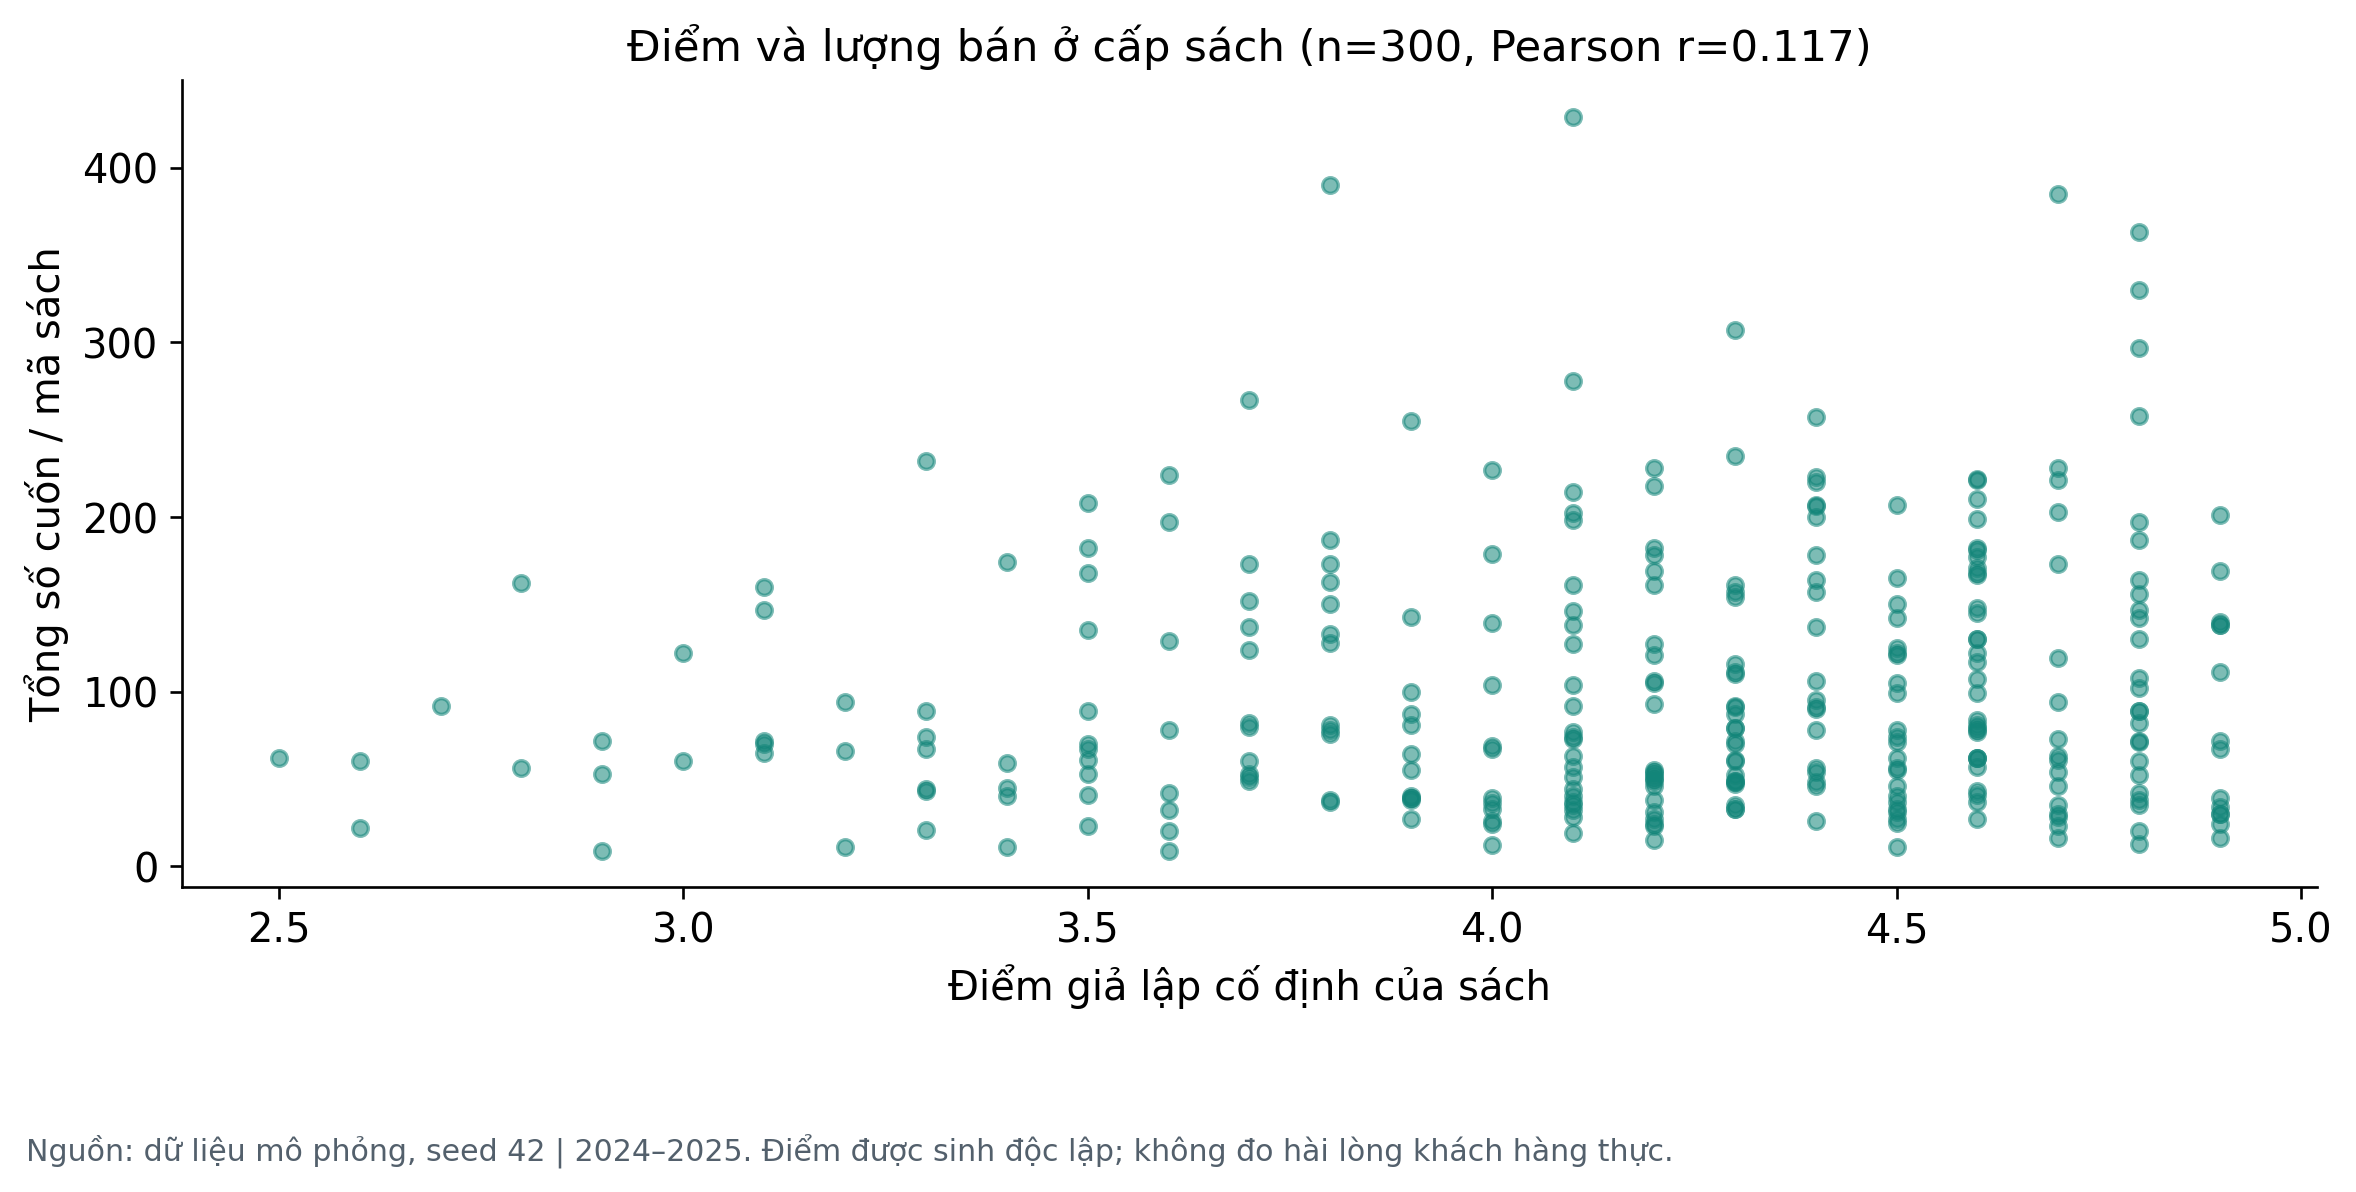

In [11]:
display(tables['books'].head(24))
display(Image(filename=str(ROOT/'charts/05_rating.png')))

### Tương quan

Biến được tính từ nhau có tương quan theo định nghĩa. Không suy ra tối ưu doanh thu hoặc nhân quả từ ma trận.

,gia_goc,gia_ban,giam_gia_thuc_te,so_luong,doanh_thu,diem_danh_gia
gia_goc,1.000,0.947,-0.015,-0.123,0.177,0.058
gia_ban,0.947,1.000,-0.302,-0.164,0.146,0.055
giam_gia_thuc_te,-0.015,-0.302,1.000,0.173,0.059,0.004
so_luong,-0.123,-0.164,0.173,1.000,0.868,0.009
doanh_thu,0.177,0.146,0.059,0.868,1.000,0.017
diem_danh_gia,0.058,0.055,0.004,0.009,0.017,1.000


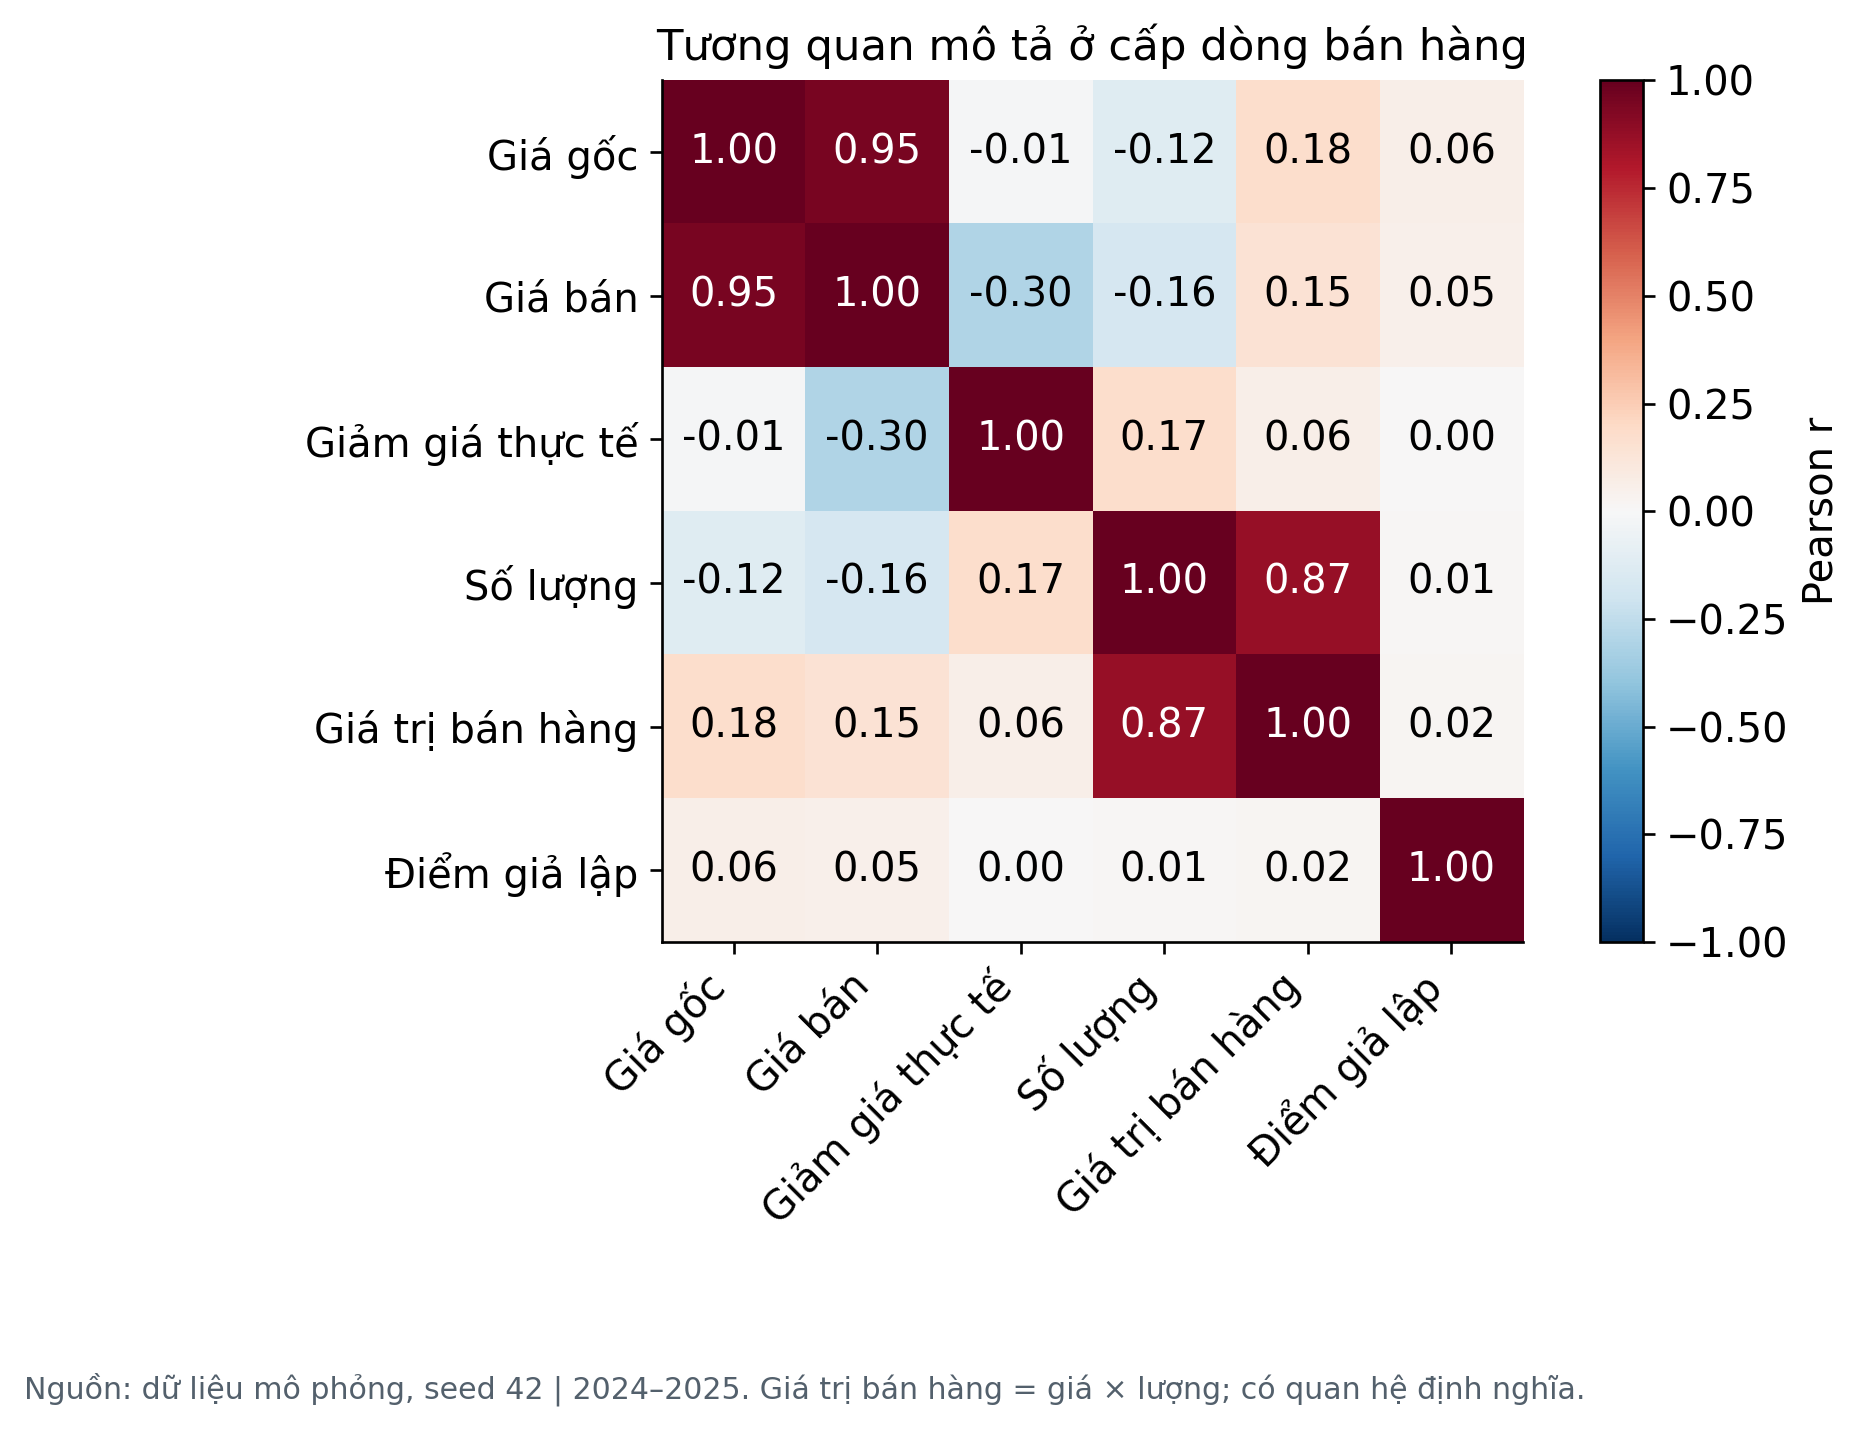

In [12]:
display(tables['correlation'].head(24))
display(Image(filename=str(ROOT/'charts/06_correlation.png')))

### Kênh và phân khúc

Tỷ trọng có mẫu số toàn bộ tập sạch; không có số thị phần thực. Dashboard thay mẫu số khi lọc.

,dinh_nghia,ty_trong_doanh_thu_pct
0,Chỉ ba sàn (marketplace),74.595
1,Ba sàn + Website (digital_channel),84.337


,kenh_ban,doanh_thu,so_luong,so_dong,ty_trong
1,Sàn A,1056171000,11278,2266,35.568
2,Sàn B,621583000,6782,1347,20.933
3,Sàn C,537306000,5764,1164,18.095
0,Cửa hàng,465105000,4364,1013,15.663
4,Website,289265000,2602,690,9.741


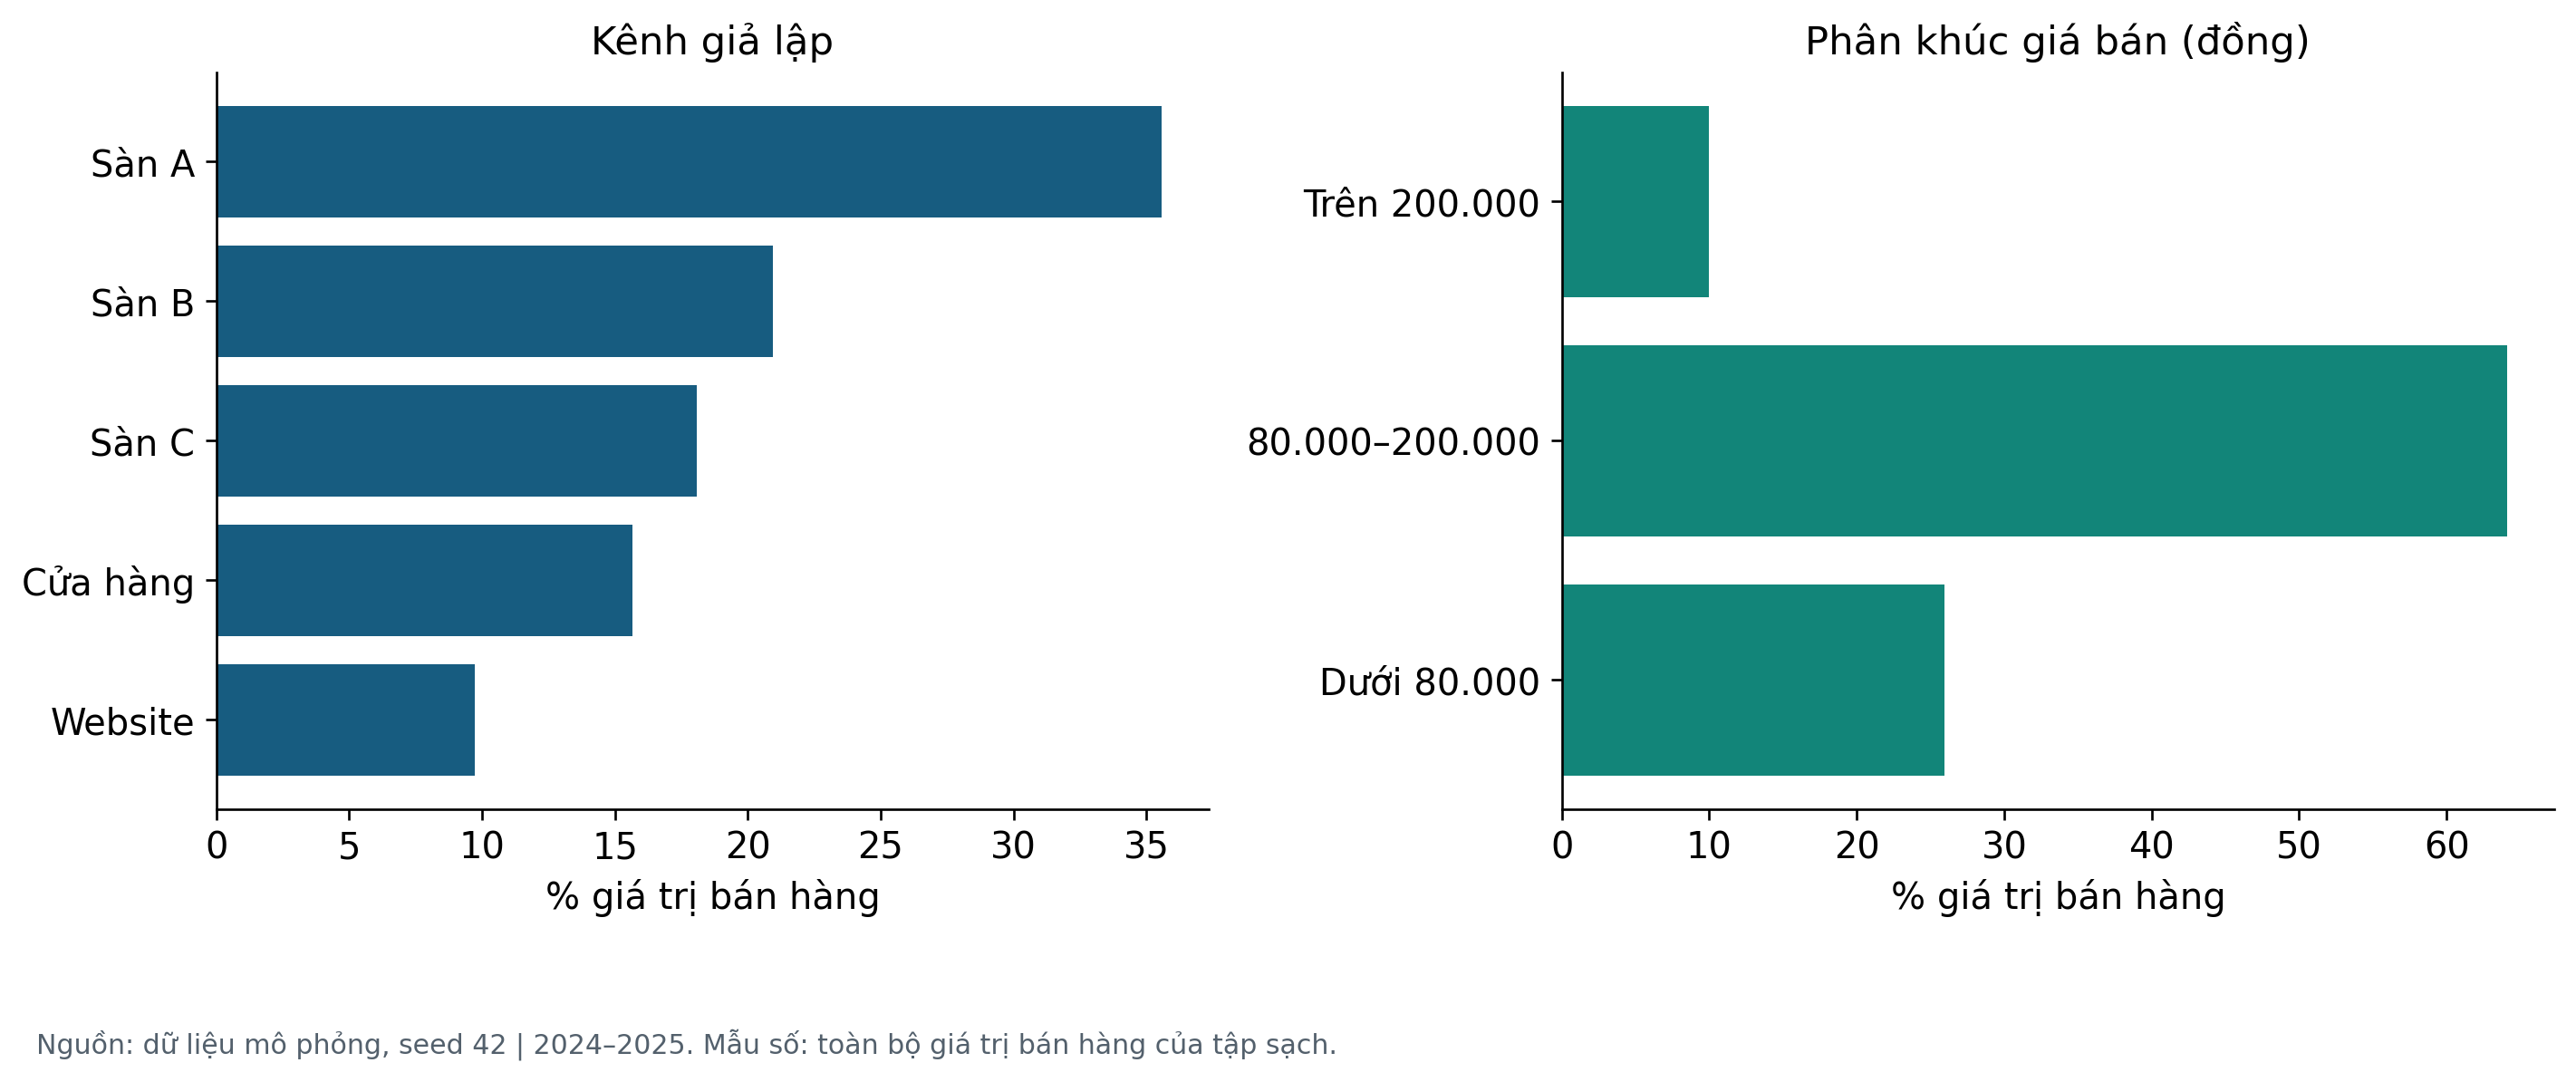

In [13]:
from src.analysis import channel_shares
mk,digital=channel_shares(df)
share=pd.DataFrame({'dinh_nghia':['Chỉ ba sàn (marketplace)','Ba sàn + Website (digital_channel)'],'ty_trong_doanh_thu_pct':[mk,digital]})
display(share)
display(tables['channel'].head(24))
display(Image(filename=str(ROOT/'charts/07_composition.png')))

## 6. Độ nhạy và sai số Monte Carlo

Số seed và số kịch bản đọc từ results/sensitivity_summary.csv, không chép tay. Phân vị giữa các lượt mô phỏng không phải khoảng tin cậy thị trường. MCSE đánh giá độ chính xác trung bình mô phỏng có điều kiện trên mô hình. Kịch bản bỏ hệ số giảm giá vẫn giữ đường ảnh hưởng qua giá bán.

,scenario,metric,R,mean,sd,mcse_mean,p025,p975
0,Cơ sở,revenue,50,"3,044,388,340.000","77,430,628.031","10,950,344.430","2,905,206,000.000","3,186,348,050.000"
1,Cơ sở,marketplace_share,50,76.242,0.763,0.108,74.912,77.625
2,Cơ sở,digital_channel_share,50,85.535,0.801,0.113,83.908,86.858
3,Cơ sở,q4_share,50,29.954,1.136,0.161,28.200,32.212
4,Cơ sở,discount_qty_r,50,0.175,0.011,0.002,0.157,0.195
5,Cơ sở,discount_qty_r_without_bulk,50,0.468,0.012,0.002,0.443,0.489
6,Cơ sở,revenue_error_pct,50,-0.315,0.119,0.017,-0.496,-0.221
7,Cơ sở,retained_pct,50,99.692,0.000,0.000,99.692,99.692
8,Không hệ số giảm giá,revenue,50,"2,271,915,280.000","64,219,308.915","9,081,981.763","2,173,319,300.000","2,388,620,675.000"
9,Không hệ số giảm giá,marketplace_share,50,73.480,1.025,0.145,71.389,75.129


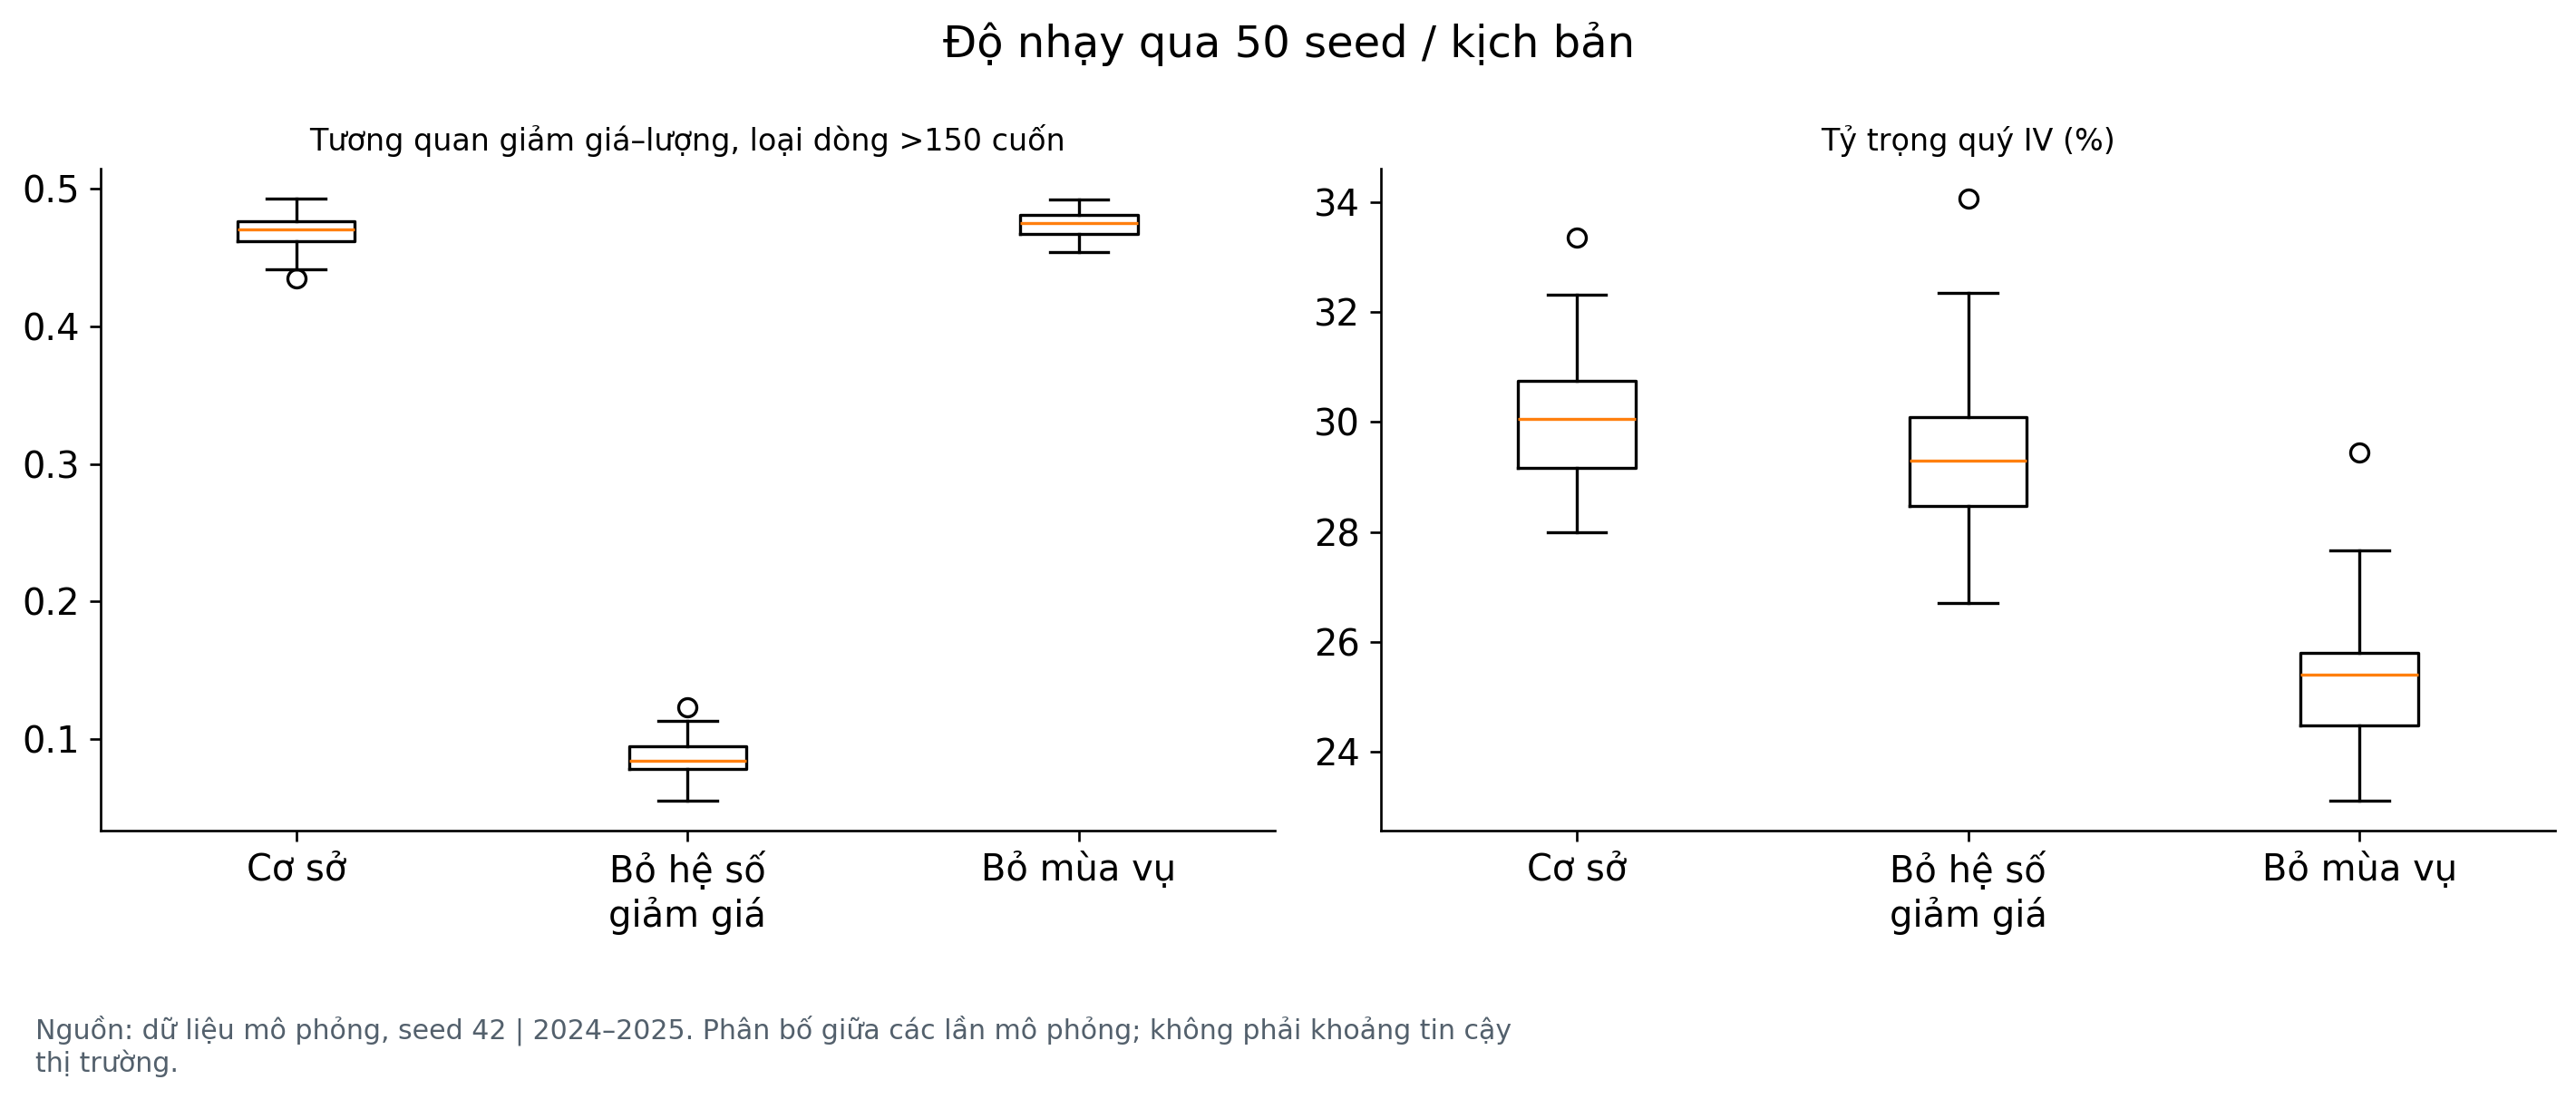

In [14]:
display(pd.read_csv(ROOT/'results/sensitivity_summary.csv'))
display(Image(filename=str(ROOT/'charts/08_sensitivity.png')))

## 7. Kiểm tra điền thiếu

Thí nghiệm che điểm MCAR một seed, không dùng catalog. Giữ thiếu không có MAE phục hồi; điền trung bình tăng độ bao phủ nhưng không đảm bảo khôi phục điểm từng sách. Cần nhiều cơ chế/seed nếu muốn kết luận tổng quát.

In [15]:
display(pd.read_csv(ROOT/'results/missing_sensitivity.csv'))

,missing_rate,method,coverage,mae_imputed,mean_rating,rating_qty_r
0,0.020,Giữ thiếu,0.980,NaN,4.217,0.009
1,0.020,Trung bình thể loại,1.000,0.365,4.217,0.009
2,0.100,Giữ thiếu,0.900,NaN,4.215,0.010
3,0.100,Trung bình thể loại,1.000,0.384,4.214,0.009
4,0.250,Giữ thiếu,0.750,NaN,4.221,0.012
5,0.250,Trung bình thể loại,1.000,0.390,4.220,0.006


## Kết luận và giới hạn

Notebook đã kiểm tra cùng dữ liệu sạch và số liệu KPI với pipeline. Các trường khớp trên tập giữ lại không đồng nghĩa tổng kỳ đầy đủ. Kết quả mô tả chỉ áp dụng cho mô phỏng. Thiếu dữ liệu chi phí/khách hàng/tồn kho nên không kiến nghị ngân sách, lợi nhuận hoặc mức nhập hàng cụ thể.

Tham khảo: [Morris et al., 2019](https://pmc.ncbi.nlm.nih.gov/articles/PMC6492164/); [NIST Box Plot](https://www.itl.nist.gov/div898/handbook/eda/section3/boxplot.htm); [pandas.cut](https://pandas.pydata.org/docs/reference/api/pandas.cut.html); [FAIR](https://www.gofair.foundation/fair-principles). Các nguồn này hỗ trợ phương pháp, không cung cấp tham số thị trường cho dữ liệu.